
# Automated Material Recognition
_Using a trash dataset to build a image based classification model_

---

## Table of Contents
1. [Introduction](#introduction)  
2. [Initial Setup](#initial-setup)  
3. [Data Ingestion](#data-ingestion)  
4. [Exploratorty Data Analysis](#exploritory-data-analaysis)  
5. [Data Cleaning & Preprocessing](#data-cleaning-preprocessing)  
6. [Modelling / Training](#modelling-training)  
7. [Evaluation](#evaluation)  
8. [Conclusion](#conclusion)



## Introduction <a id='introduction'></a>
In this notebook the key objective is to ...

## Inital Setup <a id='initial-setup'></a>

In [1]:
# Import libraries and modules
import hashlib
import numpy as np
import pandas as pd
from PIL import Image
from matplotlib import pyplot as plt
from dataset_loader import DatasetLoader
from IPython.display import display, HTML
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Define Constants
ZIP_PATH = './AI_Portfolio_Dataset.zip'
EXTRACT_DIR = './'
BATCH_SIZE = 32
NUM_WORKERS = 4
EARLY_STOPPING_PATIENCE = 15
NUM_EPOCHS = 100

## Data Ingestion <a id='data-ingestion'></a>

I will be using a DataFrame for the in memory storage of the dataset as this allows for:

- **EDA Integration** - Effective leverage of the Pandas library in exploritory data analysis
- **PyTorch Compatibility** - Custom `Dataset` classes can index into DataFrames so simple data loader building
- **Quality Tracking** - Extra columns allow for clean preprocessing without a restructure of core data 

 with the following columns:

| Column Name     | Data Type | Example Value                      | Description                           |
|-----------------|-----------|------------------------------------|---------------------------------------|
| `file_path`     | string    | `path/to/train_cardboard_000.jpg`  | Full file path                        |
| `filename`      | string    | `train_cardboard_000.jpg`          | Original filename                     |
| `split`         | string    | `train`                            | Dataset split (train/test)            |
| `label`         | string    | `cardboard`                        | String label                          |
| `label_encoded` | int       | `0`                                | Integer encoded label (0-4)           |
| `file_size`     | int       | `125340`                           | File size in bytes (optional for EDA) |
| `valid`         | bool      | `True`                             | Data quality check flag (optional)    |

In [149]:
# Load the dataset and copy the split DataFrames
loader = DatasetLoader(ZIP_PATH, EXTRACT_DIR)

train_df = loader.train_df.copy()
test_df = loader.test_df.copy()

# Show random samples of the training DataFrame
display(train_df.sample(5).reset_index(drop=True))
display(test_df.sample(5).reset_index(drop=True))

# Distinct query the split column to verify correct loading
print("Distinct splits in training DataFrame:", train_df['split'].unique())

Dataset already extracted: /home/morrison-page/CODESPACE/Assignment/Material Recognition/dataset


,file_path,filename,split,label,index,file_size,valid
0,dataset/train/train_trash_505.jpg,train_trash_505.jpg,train,trash,505,2809,True
1,dataset/train/train_glass_912.jpg,train_glass_912.jpg,train,glass,912,2402,True
2,dataset/train/train_cardboard_431.jpg,train_cardboard_431.jpg,train,cardboard,431,5397,True
3,dataset/train/train_paper_380.jpg,train_paper_380.jpg,train,paper,380,15900,True
4,dataset/train/train_cardboard_580.jpg,train_cardboard_580.jpg,train,cardboard,580,5301,True


,file_path,filename,split,label,index,file_size,valid
0,dataset/test/test_cardboard_195.jpg,test_cardboard_195.jpg,test,cardboard,195,22339,True
1,dataset/test/test_glass_000.jpg,test_glass_000.jpg,test,glass,000,7170,True
2,dataset/test/test_glass_212.jpg,test_glass_212.jpg,test,glass,212,3713,True
3,dataset/test/test_glass_316.jpg,test_glass_316.jpg,test,glass,316,4335,True
4,dataset/test/test_trash_204.jpg,test_trash_204.jpg,test,trash,204,2743,True


Distinct splits in training DataFrame: ['train']


## Exploritory Data Analaysis <a id='exploritory-data-analaysis'></a>

Firstly I will cover looking at the quality of the data itself, making sure it is unified for example all images are the same size in pixles etc

,Label,Count,Percent
0,glass,999,~25.07%
1,paper,727,~18.24%
2,cardboard,618,~15.51%
3,plastic,591,~14.83%
4,trash,525,~13.17%
5,metal,525,~13.17%


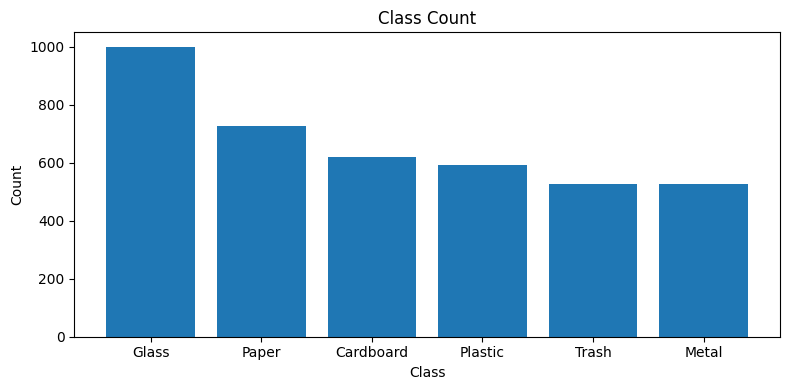

In [150]:
# Class Distribution + Counts & Percents
counts = train_df['label'].value_counts()
percentages = ('~' + (counts / counts.sum() * 100).round(2).astype(str) + '%')
display(pd.concat([counts.rename_axis('Label').reset_index(name='Count'), percentages.rename('Percent').reset_index(drop=True)], axis=1))
plt.figure(figsize=(8, 4))
plt.bar(counts.index.str.title(), counts.values)
plt.xticks(rotation=0)
plt.title('Class Count')
plt.xlabel('Class')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

We can clearly see that the dataset is skewed towards glass and also slightly favours paper, I will need to consider this when augmenting data to ensure an even class distribution 


Image Stats:


,width,height,aspect_ratio
count,3985.000000,3985.000000,3985.000000
mean,357.111669,289.583438,1.232175
std,139.266518,87.217784,0.301581
min,51.000000,100.000000,0.127500
25%,225.000000,217.000000,1.000000
50%,280.000000,262.000000,1.333333
75%,512.000000,384.000000,1.333333
max,512.000000,400.000000,5.020000



Unique Dimension Combinations:
Total unique dimension combinations: 324

Top 10 most common dimensions:


,width,height,count
323,512,384,1737
152,225,225,614
235,275,183,154
211,259,194,139
86,194,259,56
58,183,275,54
273,300,168,49
148,224,224,25
238,276,183,17
106,201,251,17



Are all images uniform? False


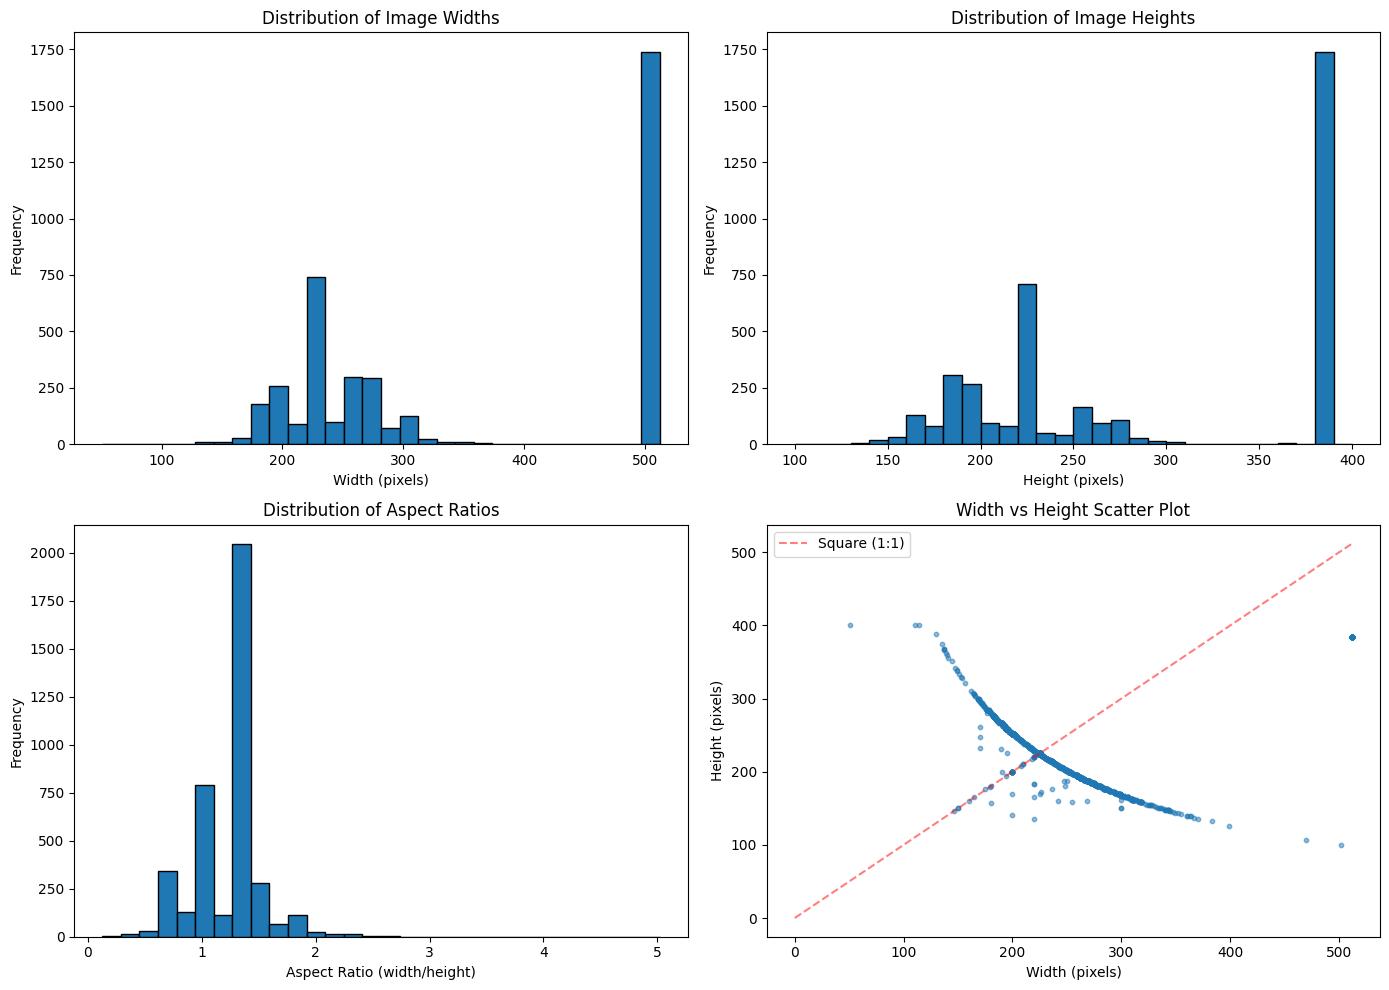

In [151]:
# Image Dimension Analysis

# Load image dimensions for all training images
dimensions = []
for idx, row in train_df.iterrows():
    try:
        with Image.open(row['file_path']) as img:
            width, height = img.size
            dimensions.append({
                'width': width,
                'height': height,
                'aspect_ratio': width / height
            })
    except Exception as e:
        print(f"Error loading {row['filename']}: {e}")

# Create dimensions DataFrame
dims_df = pd.DataFrame(dimensions)

# Basic statistics
print("\nImage Stats:")
display(dims_df.describe())

# Unique dimension combinations
unique_dims = dims_df.groupby(['width', 'height']).size().reset_index(name='count')
print(f"\nUnique Dimension Combinations:")
print(f"Total unique dimension combinations: {len(unique_dims)}")
print("\nTop 10 most common dimensions:")
display(unique_dims.sort_values('count', ascending=False).head(10))

# Check if all images are uniform
is_uniform = len(unique_dims) == 1
print(f"\nAre all images uniform? {is_uniform}")

# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Width distribution
axes[0, 0].hist(dims_df['width'], bins=30, edgecolor='black')
axes[0, 0].set_xlabel('Width (pixels)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of Image Widths')

# Height distribution
axes[0, 1].hist(dims_df['height'], bins=30, edgecolor='black')
axes[0, 1].set_xlabel('Height (pixels)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Distribution of Image Heights')

# Aspect ratio distribution
axes[1, 0].hist(dims_df['aspect_ratio'], bins=30, edgecolor='black')
axes[1, 0].set_xlabel('Aspect Ratio (width/height)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Distribution of Aspect Ratios')

# Scatter plot of width vs height
axes[1, 1].scatter(dims_df['width'], dims_df['height'], alpha=0.5, s=10)
axes[1, 1].set_xlabel('Width (pixels)')
axes[1, 1].set_ylabel('Height (pixels)')
axes[1, 1].set_title('Width vs Height Scatter Plot')
axes[1, 1].plot([0, dims_df['width'].max()], [0, dims_df['width'].max()], 'r--', alpha=0.5, label='Square (1:1)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

As demonstraited by the graphs the images are all non standard and I could benefit from translating them into a consolidated size before use in training via scaling

,file_size
count,3985.000000
mean,11050.044668
std,7987.174618
min,1186.000000
25%,4572.000000
50%,9445.000000
75%,15099.000000
max,56565.000000


,file_size_kb
count,3985.000000
mean,10.791059
std,7.799975
min,1.158203
25%,4.464844
50%,9.223633
75%,14.745117
max,55.239258


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
cardboard,618.0,11.081565,7.684612,1.631836,4.132324,8.158203,17.591309,34.099609
glass,999.0,7.673691,4.827277,1.358398,3.908203,6.057617,10.757812,33.013672
metal,525.0,12.172511,7.932236,1.765625,5.614258,10.608398,16.869141,49.162109
paper,727.0,17.606234,9.291245,5.305664,11.496582,14.214844,21.136230,55.239258
plastic,591.0,10.663002,5.558917,1.602539,6.336426,9.926758,14.602539,30.706055
trash,525.0,5.706308,4.519881,1.158203,2.863281,3.886719,6.765625,35.428711


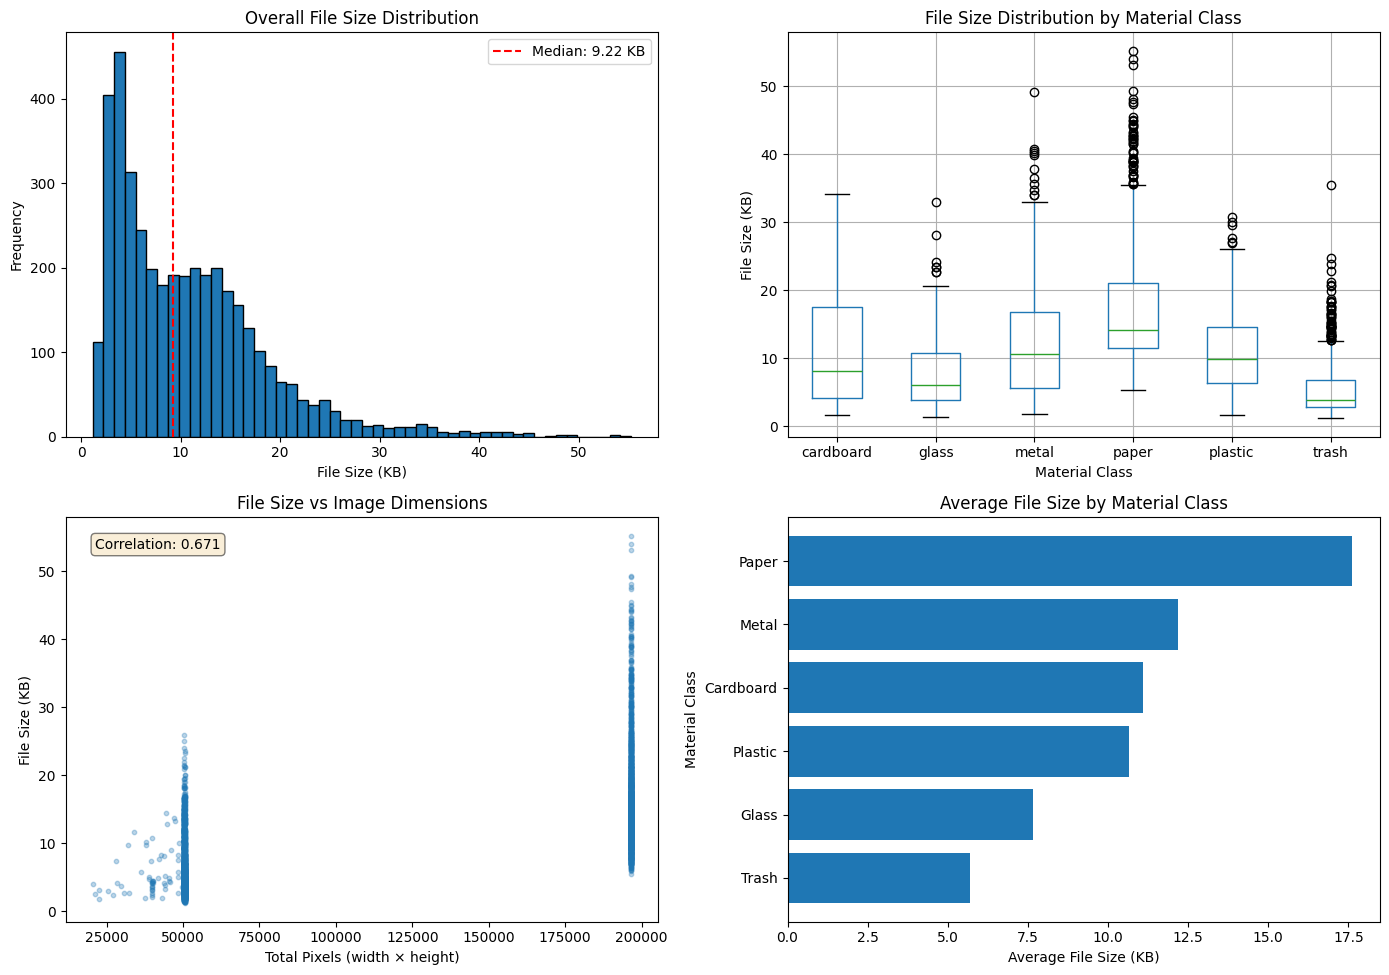

Number of outliers (using IQR method): 116 (2.91%)
Lower bound: -10.96 KB, Upper bound: 30.17 KB


,Mean (KB),Std Dev (KB),Median (KB),Count
label,,,,
paper,17.61,9.29,14.21,727
metal,12.17,7.93,10.61,525
cardboard,11.08,7.68,8.16,618
plastic,10.66,5.56,9.93,591
glass,7.67,4.83,6.06,999
trash,5.71,4.52,3.89,525


,mean,median,std
label,,,
paper,0.182,0.178,0.099
metal,0.106,0.095,0.051
plastic,0.097,0.082,0.055
cardboard,0.097,0.090,0.035
glass,0.090,0.079,0.044
trash,0.079,0.071,0.036


In [152]:
# File Size Analysis

display(HTML("<h2>File Size Statistics (bytes)</h2>"))
display(train_df['file_size'].describe().to_frame())

# Convert to KB for easier interpretation
train_df['file_size_kb'] = train_df['file_size'] / 1024

display(HTML("<h2>File Size Statistics (KB)</h2>"))
display(train_df['file_size_kb'].describe().to_frame())

# File size distribution per class
display(HTML("<h2>File Size Statistics by Material Class (KB)</h2>"))
display(train_df.groupby('label')['file_size_kb'].describe())

# Create visualisations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Overall file size distribution
axes[0, 0].hist(train_df['file_size_kb'], bins=50, edgecolor='black')
axes[0, 0].set_xlabel('File Size (KB)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Overall File Size Distribution')
axes[0, 0].axvline(train_df['file_size_kb'].median(), color='red', linestyle='--', label=f'Median: {train_df["file_size_kb"].median():.2f} KB')
axes[0, 0].legend()

# File size distribution by class
train_df.boxplot(column='file_size_kb', by='label', ax=axes[0, 1])
axes[0, 1].set_xlabel('Material Class')
axes[0, 1].set_ylabel('File Size (KB)')
axes[0, 1].set_title('File Size Distribution by Material Class')
axes[0, 1].get_figure().suptitle('')  # Remove automatic title

# Merge dimensions data with train_df for correlation analysis
train_df_with_dims = train_df.copy()
train_df_with_dims['width'] = dims_df['width']
train_df_with_dims['height'] = dims_df['height']
train_df_with_dims['pixels'] = dims_df['width'] * dims_df['height']

# Correlation: File size vs total pixels
axes[1, 0].scatter(train_df_with_dims['pixels'], train_df_with_dims['file_size_kb'], alpha=0.3, s=10)
axes[1, 0].set_xlabel('Total Pixels (width × height)')
axes[1, 0].set_ylabel('File Size (KB)')
axes[1, 0].set_title('File Size vs Image Dimensions')

# Calculate correlation
correlation = train_df_with_dims[['pixels', 'file_size_kb']].corr().iloc[0, 1]
axes[1, 0].text(0.05, 0.95, f'Correlation: {correlation:.3f}', 
                transform=axes[1, 0].transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Average file size by material class
avg_size_by_class = train_df.groupby('label')['file_size_kb'].mean().sort_values()
axes[1, 1].barh(avg_size_by_class.index.str.title(), avg_size_by_class.values)
axes[1, 1].set_xlabel('Average File Size (KB)')
axes[1, 1].set_ylabel('Material Class')
axes[1, 1].set_title('Average File Size by Material Class')

plt.tight_layout()
plt.show()

# Identify unusual files
display(HTML("<h2>Unusual File Sizes</h2>"))
q1 = train_df['file_size_kb'].quantile(0.25)
q3 = train_df['file_size_kb'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = train_df[(train_df['file_size_kb'] < lower_bound) | (train_df['file_size_kb'] > upper_bound)]
print(f"Number of outliers (using IQR method): {len(outliers)} ({len(outliers)/len(train_df)*100:.2f}%)")
print(f"Lower bound: {lower_bound:.2f} KB, Upper bound: {upper_bound:.2f} KB")

# Statistical test: Check if file size differs significantly across classes
display(HTML("<h2>File Size Pattern Analysis by Material</h2>"))
compression_analysis = train_df.groupby('label').agg({
    'file_size_kb': ['mean', 'std', 'median'],
    'filename': 'count'
}).round(2)
compression_analysis.columns = ['Mean (KB)', 'Std Dev (KB)', 'Median (KB)', 'Count']
display(compression_analysis.sort_values('Mean (KB)', ascending=False))

# Calculate compression ratio (file size per pixel)
train_df_with_dims['bytes_per_pixel'] = train_df['file_size'] / train_df_with_dims['pixels']
display(HTML("<h2>Compression Ratio Analysis (Bytes per Pixel)</h2>"))
compression_by_class = train_df_with_dims.groupby('label')['bytes_per_pixel'].agg(['mean', 'median', 'std']).round(3)
display(compression_by_class.sort_values('mean', ascending=False))

All the research on the file sizes is showing me is what classes have more detailed images and thus what classes the model may have a hard time understanding.

In [153]:
# Image Quality Checks
display(HTML("<h1>Image Quality Analysis</h1>"))

# Initialize tracking variables
corrupted_images = []
dimension_issues = []
channel_issues = []
greyscale_as_rgb = []
image_modes = {}

# Define thresholds for dimension checks
MIN_DIM = 50  # Minimum reasonable dimension
MAX_DIM = 5000  # Maximum reasonable dimension

for idx, row in train_df.iterrows():
    try:
        with Image.open(row['file_path']) as img:
            width, height = img.size
            mode = img.mode
            
            # Track image modes
            image_modes[mode] = image_modes.get(mode, 0) + 1
            
            # Check for dimension issues
            if width < MIN_DIM or height < MIN_DIM or width > MAX_DIM or height > MAX_DIM:
                dimension_issues.append({
                    'filename': row['filename'],
                    'width': width,
                    'height': height,
                    'issue': 'Too small' if (width < MIN_DIM or height < MIN_DIM) else 'Too large'
                })
            
            # Check channel/mode issues
            if mode not in ['RGB', 'L']:  # L is greyscale
                channel_issues.append({
                    'filename': row['filename'],
                    'mode': mode,
                    'size': (width, height)
                })
            
            # Check for greyscale images saved as RGB
            if mode == 'RGB':
                img_array = np.array(img)
                # Check if all three channels are identical (greyscale masquerading as RGB)
                if img_array.shape[2] == 3:
                    r, g, b = img_array[:,:,0], img_array[:,:,1], img_array[:,:,2]
                    if np.array_equal(r, g) and np.array_equal(g, b):
                        greyscale_as_rgb.append({
                            'filename': row['filename'],
                            'size': (width, height)
                        })
                        
    except Exception as e:
        corrupted_images.append({
            'filename': row['filename'],
            'error': str(e)
        })

# Print Results
display(HTML("<h2>Image Mode Distribution</h2>"))
for mode, count in sorted(image_modes.items(), key=lambda x: x[1], reverse=True):
    percentage = (count / len(train_df)) * 100
    print(f"{mode}: {count} images ({percentage:.2f}%)")

display(HTML("<h2>Corrupted/Unreadable Images</h2>"))
print(f"Total corrupted images: {len(corrupted_images)}")
if corrupted_images:
    corrupted_df = pd.DataFrame(corrupted_images)
    display(corrupted_df)
else:
    print("No corrupted images found!")

# Dimension Issues
display(HTML("<h2>Dimension Issues</h2>"))
print(f"Total images with dimension issues: {len(dimension_issues)}")
print(f"(Thresholds: MIN={MIN_DIM}px, MAX={MAX_DIM}px)")
if dimension_issues:
    dim_issues_df = pd.DataFrame(dimension_issues)
    print("\nBy issue type:")
    display(dim_issues_df.groupby('issue').size())
    print("\nSample of problematic images:")
    display(dim_issues_df.head(10))
else:
    print("No dimension issues found!")

# Channel/Mode Issues
display(HTML("<h2>Chanel/Mode Issues</h2>"))
print(f"Total images with unexpected modes: {len(channel_issues)}")
if channel_issues:
    channel_df = pd.DataFrame(channel_issues)
    display(channel_df)
else:
    print("All images are in expected modes (RGB or L)!")

# Greyscale Issues
display(HTML("<h2>Greyscale Images Saved as RGB</h2>"))
print(f"Total greyscale-as-RGB images: {len(greyscale_as_rgb)}")
if greyscale_as_rgb:
    percentage = (len(greyscale_as_rgb) / len(train_df)) * 100
    print(f"Percentage: {percentage:.2f}%")
    
    # Show distribution by material class
    greyscale_files = [item['filename'] for item in greyscale_as_rgb]
    greyscale_in_df = train_df[train_df['filename'].isin(greyscale_files)]
    
    print("\nDistribution by material class:")
    display(greyscale_in_df['label'].value_counts().to_frame(name='Count'))
    
    print("\nSample greyscale-as-RGB images:")
    display(pd.DataFrame(greyscale_as_rgb).head(10))
else:
    print("No greyscale images masquerading as RGB found!")

# Summary Visualisation
display(HTML("<h2>Overall Quality Summary</h2>"))
quality_summary = {
    'Total Images': len(train_df),
    'Corrupted': len(corrupted_images),
    'Dimension Issues': len(dimension_issues),
    'Channel Issues': len(channel_issues),
    'Greyscale as RGB': len(greyscale_as_rgb),
    'Healthy Images': len(train_df) - len(corrupted_images) - len(dimension_issues) - len(channel_issues)
}

summary_df = pd.DataFrame(list(quality_summary.items()), columns=['Category', 'Count'])
summary_df['Percentage'] = (summary_df['Count'] / len(train_df) * 100).round(2)
display(summary_df.style.hide(axis='index'))

# Flag problematic images in the DataFrame
if corrupted_images or dimension_issues or channel_issues:
    problematic_files = (
        [item['filename'] for item in corrupted_images] +
        [item['filename'] for item in dimension_issues] +
        [item['filename'] for item in channel_issues] +
        [item['filename'] for item in greyscale_as_rgb]
    )
    train_df.loc[train_df['filename'].isin(problematic_files), 'valid'] = False
    print(f"\nMarked {len(problematic_files)} problematic images with valid=False")

RGB: 3973 images (99.70%)
P: 12 images (0.30%)


Total corrupted images: 0
No corrupted images found!


Total images with dimension issues: 0
(Thresholds: MIN=50px, MAX=5000px)
No dimension issues found!


Total images with unexpected modes: 12


,filename,mode,size
0,train_trash_093.jpg,P,"(225, 225)"
1,train_glass_415.jpg,P,"(225, 225)"
2,train_trash_199.jpg,P,"(225, 225)"
3,train_trash_076.jpg,P,"(198, 254)"
4,train_paper_460.jpg,P,"(190, 200)"
5,train_trash_227.jpg,P,"(225, 225)"
6,train_trash_185.jpg,P,"(225, 225)"
7,train_trash_458.jpg,P,"(225, 225)"
8,train_trash_078.jpg,P,"(225, 225)"
9,train_trash_308.jpg,P,"(224, 224)"


Total greyscale-as-RGB images: 104
Percentage: 2.61%

Distribution by material class:


,Count
label,
glass,42
paper,30
trash,16
metal,13
plastic,3



Sample greyscale-as-RGB images:


,filename,size
0,train_glass_913.jpg,"(225, 225)"
1,train_glass_167.jpg,"(225, 225)"
2,train_glass_921.jpg,"(225, 225)"
3,train_glass_835.jpg,"(176, 286)"
4,train_paper_342.jpg,"(225, 225)"
5,train_plastic_344.jpg,"(225, 225)"
6,train_glass_272.jpg,"(225, 225)"
7,train_glass_075.jpg,"(225, 225)"
8,train_glass_331.jpg,"(225, 225)"
9,train_glass_948.jpg,"(220, 229)"


Category,Count,Percentage
Total Images,3985,100.000000
Corrupted,0,0.000000
Dimension Issues,0,0.000000
Channel Issues,12,0.300000
Greyscale as RGB,104,2.610000
Healthy Images,3973,99.700000



Marked 116 problematic images with valid=False


Looking at the quality summary I can see that the quantity of images that use P rather than RGB is negligable so will just drop them in preprocessing.

As for the Greyscale images stored in RGB format, they will work in the planned architecture however I will need to make sure their class distribution isn't skewed either by using augmentation or dropping the data to avoid the model compensating towards glass (as that is the most represented class by greyscale images) 

In [154]:
def compute_sha256(file_path: str) -> str | None:
    sha256_hash = hashlib.sha256()
    try:
        with open(file_path, "rb") as f:
            for byte_block in iter(lambda: f.read(4096), b""):
                sha256_hash.update(byte_block)
        return sha256_hash.hexdigest()
    except Exception as e:
        print(f"Error computing hash for {file_path}: {e}")
        return None

In [155]:
# Compute hashes for all images in DataFrame
train_df['sha256'] = train_df['file_path'].apply(compute_sha256)
hash_counts = train_df['sha256'].value_counts()
duplicate_hashes = hash_counts[hash_counts > 1]

# Print duplicate hashes and their occurrences
if not duplicate_hashes.empty:
    print("Duplicate hashes found:")
    print(duplicate_hashes)
else:
    print("No duplicate hashes found.")

No duplicate hashes found.


#### More EDA that I could look into:

- Further do quality checks on the smallest 10% of files including larger files or ones that in the (display res vs file size) chart doesn't fit the established curve / a rough line best fit 
- Brightness and Contrast Analysis (Mean intesnsity across images per class)
- Possible RGB Distribution per class (Affect what & how I augment later on)

## Data Cleaning & Preprocessing <a id='data-cleaning-preprocessing'></a>

Lets get the easy stuff out of the way first by dropping all rows which were marked as invalid in our EDA:

- Images with a mode of P as unable to be accepted via the CNN architecture I am going with
- Greyscale images saved as RGB (Easier than attempting to balance with augmentation, may look at later on)

In [156]:
# Show Invalid Rows
invalid_row_count = train_df['valid'].value_counts().get(False, 0)
print(f"Invalid Rows: {invalid_row_count}")

# Drop Invalid Rows 
train_df = train_df[train_df['valid']].copy()
invalid_row_count = train_df['valid'].value_counts().get(False, 0)
print(f"Invalid Rows: {invalid_row_count}")

Invalid Rows: 116
Invalid Rows: 0


> Note that the Train/Test Split has already been performed, that is why it is not done here and I am Only allowed to validate and modify the train set so no prep of the test/validation set is done here.

In [157]:
def encode_labels() -> None:
    label_mapping = {
        'cardboard': 0,
        'glass': 1,
        'metal': 2,
        'paper': 3,
        'plastic': 4,
        'trash': 5
    }

    train_df['label_encoded'] = train_df['label'].map(label_mapping)
    test_df['label_encoded'] = test_df['label'].map(label_mapping)

# Encode Labels & Validate
encode_labels()
print("Verify Label Encodings:")
display(train_df.head())
display(test_df.head())

Verify Label Encodings:


,file_path,filename,split,label,index,file_size,valid,file_size_kb,sha256,label_encoded
0,dataset/train/train_cardboard_505.jpg,train_cardboard_505.jpg,train,cardboard,505,14698,True,14.353516,9aa6cf0e9a86de7a3ce785cda8dcedf23539392a690e37...,0
1,dataset/train/train_paper_091.jpg,train_paper_091.jpg,train,paper,091,39862,True,38.927734,e2579b837bd6b550f3a2dbad88977751795167a35b7b88...,3
2,dataset/train/train_paper_535.jpg,train_paper_535.jpg,train,paper,535,9505,True,9.282227,243e31ab005786c41b5e08793f439cd61877d4b52626ae...,3
3,dataset/train/train_trash_165.jpg,train_trash_165.jpg,train,trash,165,10534,True,10.287109,20018f7c4b30f387edbca44d6b4b1233f65fb0e1949921...,5
4,dataset/train/train_plastic_080.jpg,train_plastic_080.jpg,train,plastic,080,13131,True,12.823242,a42de206a88426c033ab5c2482a5ac7ec3e81ce1695fb8...,4


,file_path,filename,split,label,index,file_size,valid,label_encoded
0,dataset/test/test_paper_092.jpg,test_paper_092.jpg,test,paper,092,9489,True,3
1,dataset/test/test_paper_218.jpg,test_paper_218.jpg,test,paper,218,13154,True,3
2,dataset/test/test_cardboard_245.jpg,test_cardboard_245.jpg,test,cardboard,245,10275,True,0
3,dataset/test/test_metal_212.jpg,test_metal_212.jpg,test,metal,212,6239,True,2
4,dataset/test/test_trash_146.jpg,test_trash_146.jpg,test,trash,146,16017,True,5


In [158]:
# Drop unnecessary EDA columns from DFs
train_df.drop(columns=[
    'label',
    'index',
    'file_size_kb',
    'file_size',
    'valid',
    'sha256'
    ], inplace=True
)

test_df.drop(columns=[
    'label',
    'index',
    'file_size',
    'valid'
    ], inplace=True
)

train_df.rename(columns={'label_encoded': 'label'}, inplace=True)
test_df.rename(columns={'label_encoded': 'label'}, inplace=True)

display(HTML("<h2>Verify Column Drops:</h2>"))
display(train_df.head())
display(test_df.head())

,file_path,filename,split,label
0,dataset/train/train_cardboard_505.jpg,train_cardboard_505.jpg,train,0
1,dataset/train/train_paper_091.jpg,train_paper_091.jpg,train,3
2,dataset/train/train_paper_535.jpg,train_paper_535.jpg,train,3
3,dataset/train/train_trash_165.jpg,train_trash_165.jpg,train,5
4,dataset/train/train_plastic_080.jpg,train_plastic_080.jpg,train,4


,file_path,filename,split,label
0,dataset/test/test_paper_092.jpg,test_paper_092.jpg,test,3
1,dataset/test/test_paper_218.jpg,test_paper_218.jpg,test,3
2,dataset/test/test_cardboard_245.jpg,test_cardboard_245.jpg,test,0
3,dataset/test/test_metal_212.jpg,test_metal_212.jpg,test,2
4,dataset/test/test_trash_146.jpg,test_trash_146.jpg,test,5


## Modelling / Training <a id='modelling-training'></a>

In [159]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


Provide some explanation regarding the transforms below and the reasoning behind choices such as resizing cropping colour jitter etc

In [160]:
# Define transforms
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # ImageNet RBG Means & Standard Deviations
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # ImageNet RBG Means & Standard Deviations
])

Explain that this is the data set class which inherits from Pi torches data set class which allows for automatic loading based on the defined __getitem__ and __len__ methods

In [161]:
class MaterialDataset(Dataset):
    """Custom Dataset for material classification"""
    
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
    
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        img_path = self.dataframe.loc[idx, 'file_path']
        label = self.dataframe.loc[idx, 'label']
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

In [162]:
# Create datasets & look at size
train_dataset = MaterialDataset(train_df, transform=train_transforms)
val_dataset = MaterialDataset(test_df, transform=val_transforms)

print(f"\nDataset sizes:")
print(f"Train: {len(train_dataset)}")
print(f"Validation: {len(val_dataset)}")


Dataset sizes:
Train: 3869
Validation: 1704


Explain predicament of balancing class distribution and how the resolution was to use a weighted random sampler to handle the class imbalance

In [163]:
# Create WeightedRandomSampler for handling class imbalance
class_counts = train_df['label'].value_counts().sort_index()
class_weights = 1.0 / class_counts
sample_weights = train_df['label'].map(class_weights).values

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"\nDataLoader configuration:")
print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")


DataLoader configuration:
Batch size: 32
Training batches: 121
Validation batches: 54


Explain choice of model architecture In this case using a convolutional neural network that has things like transfer learning based on Resnet 101 waits for the Imagenet 1KV2 (the 2020 run)

Also state that I tried 50 & 152 and 101 yeilded the best results for consistency, performance and accuracy

In [164]:
class MaterialClassifier(nn.Module):
    """CNN classifier using pretrained ResNet-101 backbone"""
    
    def __init__(self, num_classes=6, freeze_backbone=True):
        super(MaterialClassifier, self).__init__()
        
        # Load pretrained ResNet-101
        self.backbone = models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V2)
        
        # Freeze backbone if specified
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
        
        # Replace final FC layer
        num_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        return self.backbone(x)
    
    def unfreeze_backbone(self, num_layers=10):
        """Unfreeze top layers of backbone for fine-tuning"""
        # Get all parameters
        params = list(self.backbone.parameters())
        # Unfreeze last num_layers
        for param in params[-num_layers:]:
            param.requires_grad = True

In [ ]:
# Initialize model
model = MaterialClassifier(num_classes=6, freeze_backbone=True)
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nModel Architecture: ResNet-101")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

# Define loss function with class weights
class_weights_tensor = torch.FloatTensor([1.0 / count for count in class_counts.values])
class_weights_tensor = class_weights_tensor.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Define optimizer (Adam - "the goat")
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=1e-4
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3
)


Model Architecture: ResNet-50
Total parameters: 43,026,246
Trainable parameters: 526,086
Frozen parameters: 42,500,160


talk about early stopping Why it's significant and how I've chosen to implement it And with varying patience

In [166]:
class EarlyStopping:
    """Early stopping to stop training when validation loss doesn't improve"""
    
    def __init__(self, patience=7, min_delta=0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model = None
    
    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model = model.state_dict().copy()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.verbose:
                print(f"EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model = model.state_dict().copy()
            self.counter = 0

# Instantiate and use Early Stopping
early_stopping = EarlyStopping(patience=EARLY_STOPPING_PATIENCE, verbose=True)

In [ ]:
print("\nTraining configuration:")
print(f"Loss function: CrossEntropyLoss (with class weights)")
print(f"Optimizer: Adam (lr=0.001, weight_decay=1e-4)")
print(f"LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)")
print(f"Early stopping: Enabled (patience={EARLY_STOPPING_PATIENCE})")
print("\nReady to train!")

# Training function
def train_epoch(model, loader, criterion, optimizer, device):
    """Train for one epoch"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        # Statistics
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    
    return epoch_loss, epoch_acc

# Validation function
def validate(model, loader, criterion, device):
    """Validate the model"""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    
    return epoch_loss, epoch_acc

# Training loop
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'lr': []
}

print("\n" + "="*50)
print("STARTING TRAINING")
print("="*50)

for epoch in range(NUM_EPOCHS):
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    
    # Validate
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    
    # Record history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['lr'].append(optimizer.param_groups[0]['lr'])
    
    # Print progress
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print(f"  LR: {optimizer.param_groups[0]['lr']:.6f}")
    
    # Learning rate scheduling
    scheduler.step(val_loss)
    
    # Early stopping
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print("\nEarly stopping triggered!")
        model.load_state_dict(early_stopping.best_model)
        break
    
    # Unfreeze backbone after 10 epochs for fine-tuning
    if epoch == 10:
        print("\n" + "="*50)
        print("UNFREEZING BACKBONE FOR FINE-TUNING")
        print("="*50)
        model.unfreeze_backbone(num_layers=20)
        optimizer = optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=0.0001,  # Lower learning rate for fine-tuning
            weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode='min',
            factor=0.5,
            patience=3
        )

print("\n" + "="*50)
print("TRAINING COMPLETE")
print("="*50)


Training configuration:
Loss function: CrossEntropyLoss (with class weights)
Optimizer: Adam (lr=0.001, weight_decay=1e-4)
LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)
Early stopping: Enabled (patience=15)

Ready to train!

STARTING TRAINING


Epoch [1/100]
  Train Loss: 0.8858, Train Acc: 0.6805
  Val Loss: 0.4436, Val Acc: 0.8468
  LR: 0.001000
Epoch [2/100]
  Train Loss: 0.5571, Train Acc: 0.8012
  Val Loss: 0.3804, Val Acc: 0.8603
  LR: 0.001000
Epoch [3/100]
  Train Loss: 0.4999, Train Acc: 0.8183
  Val Loss: 0.3517, Val Acc: 0.8820
  LR: 0.001000
Epoch [4/100]
  Train Loss: 0.4708, Train Acc: 0.8315
  Val Loss: 0.3291, Val Acc: 0.8791
  LR: 0.001000
Epoch [5/100]
  Train Loss: 0.4678, Train Acc: 0.8379
  Val Loss: 0.2879, Val Acc: 0.9055
  LR: 0.001000
Epoch [6/100]
  Train Loss: 0.4745, Train Acc: 0.8268
  Val Loss: 0.3099, Val Acc: 0.8791
  LR: 0.001000
EarlyStopping counter: 1/15
Epoch [7/100]
  Train Loss: 0.4150, Train Acc: 0.8545
  Val Loss: 0.2893, Val Acc: 0.8991
  LR: 0.001000
EarlyStopping counter: 2/15
Epoch [8/100]
  Train Loss: 0.4112, Train Acc: 0.8555
  Val Loss: 0.2937, Val Acc: 0.8867
  LR: 0.001000
EarlyStopping counter: 3/15
Epoch [9/100]
  Train Loss: 0.3984, Train Acc: 0.8488
  Val Loss: 0.2877, Va

## Evaluation <a id='evaluation'></a>

This section checks how the model performed by graphing the loss and accuracy of the model per epoch for the train and the test/validation sets & also saving the best model weights after the training & validation.

> NOTE: That the model doesn't take all too long to train so that is why I haven't opted to periodically save the weights during its training cycle.

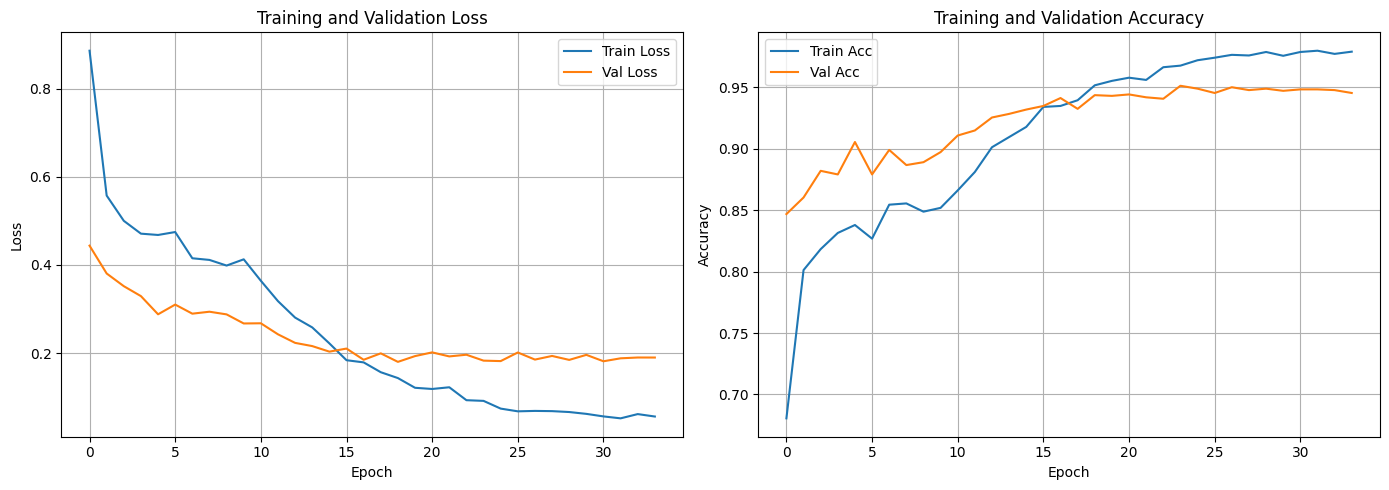


Best model saved as 'best_material_classifier_95.13.pth'
Best Validation Accuracy: 95.13%


In [ ]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Loss plot
axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True)
# Accuracy plot
axes[1].plot(history['train_acc'], label='Train Acc')
axes[1].plot(history['val_acc'], label='Val Acc')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

# Calculate best validation accuracy and save model with accuracy in filename
best_val_acc = max(history['val_acc'])
best_val_acc_pct = best_val_acc * 100
model_filename = f'best_material_classifier_{best_val_acc_pct:.2f}.pth'

torch.save(model.state_dict(), model_filename)
print(f"\n{'='*50}")
print(f"Best model saved as '{model_filename}'")
print(f"Best Validation Accuracy: {best_val_acc_pct:.2f}%")
print(f"{'='*50}")


## Conclusion <a id='conclusion'></a>
_Add some profound detail about the result of this excercise_

_Things that could have been done better:_

- ...

---

## Appendix
- **Author:** Morrison Page
- **Date:** 14/12/2025
- **Environment:** `Kernal - Python 3.12.3`
